You are a data analyst working for a tech company closely monitoring the AI tools market. You want to understand the evolving popularity of three major AI tools, ChatGPT, Gemini, and Microsoft Copilot, and identify which tool is gaining the most traction and how they compare over time.


<img src="ai_tools.jpg" align="center"/>

You'll work with real-world time series data that captures the global interest in these tools over several weeks. Your goal is to analyze this data, uncover patterns, and provide actionable insights to help your company make informed decisions. This might include determining where to focus marketing efforts, predicting future trends, or identifying potential areas for improvement.

Are you ready to help your company stay ahead of the curve in the competitive AI tools market? Let's get started!

### The Data

The Google Trends data is available as a CSV file `ai_tools_comparison.csv`.
The data contains the number of worldwide searches for chatGpt, Gemini, and Microsoft Copilot over the past 12 months as of September 2024. 
<!--- Link to query: https://trends.google.com/trends/explore?q=chatgpt,gemini,%2Fg%2F11tsqm45vd&hl=en-US -->

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
trends = pd.read_csv('ai_tools_comparison.csv')

# Inspect the data
trends.head()

,week,chatgpt,gemini,microsoft_copilot
0,2023-08-27,56,3,1
1,2023-09-03,56,3,1
2,2023-09-10,63,3,1
3,2023-09-17,64,3,1
4,2023-09-24,66,3,1


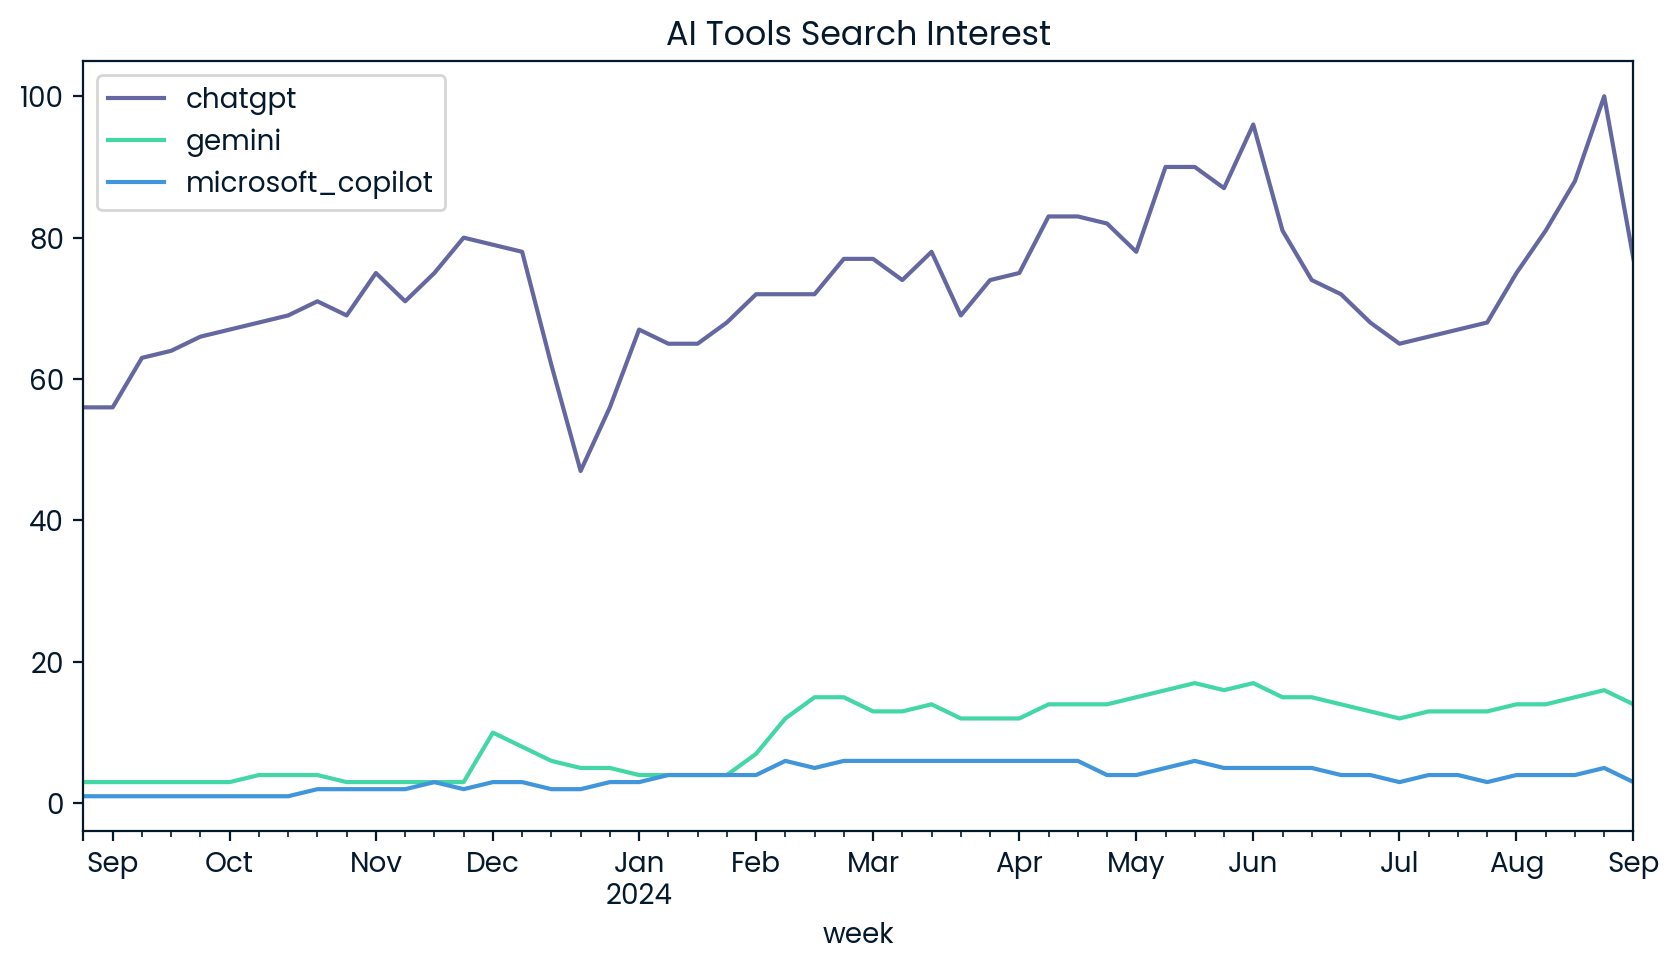

most_consistent_tool: chatgpt
gpt_dip: December 2023
best_month: May


In [4]:
# Start coding here
# Use as many cells as you need


import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the data and format the dates
trends = pd.read_csv('ai_tools_comparison.csv')
date_col = trends.columns[0]
trends[date_col] = pd.to_datetime(trends[date_col])
trends.set_index(date_col, inplace=True)

# Visualize the trends to confirm
trends.plot(figsize=(10, 5), title="AI Tools Search Interest")
plt.show()

# --- Q1: Most consistent growth ---
# Calculate week-over-week percentage change, get standard deviation, and find the minimum

most_consistent_tool = trends.pct_change().std().idxmin()

# --- Q2: ChatGPT's lowest point ---

gpt_col = [col for col in trends.columns if 'chatgpt' in col.lower()][0]
gpt_drop_date = trends[gpt_col].idxmin()
gpt_dip = gpt_drop_date.strftime('%B %Y') 

# --- Q3: Highest average interest month ---

monthly_data = trends.resample('M').mean() 
best_month_date = monthly_data.mean(axis=1).idxmax()
best_month = best_month_date.strftime('%B') 

# Print the final variables to verify 

print(f"most_consistent_tool: {most_consistent_tool}")
print(f"gpt_dip: {gpt_dip}")
print(f"best_month: {best_month}")
